# DS605 – Lab 7: Image Representation, PCA, Eigenfaces and Face Recognition
**Dataset:** AT&T Database of Faces (ORL) – 40 subjects × 10 grayscale images (112 × 92 px)

**Pipeline:** Images → Grayscale pixel matrix → Flatten → Mean-centering → PCA / SVD → Explained variance → Eigenfaces → Reduced representation → Reconstruction → Similarity matching → ML classification

**Rules followed:** all PCA / eigenface maths is done with **NumPy linear algebra only** (`np.linalg.eigh`, `np.linalg.svd`). Scikit-learn is used **only** in Part D (traditional classifiers).

> **Before running:** set the variable `path` in the next cell to the folder that contains the downloaded face images.

In [9]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kasikrit/att-database-of-faces")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\rutup\.cache\kagglehub\datasets\kasikrit\att-database-of-faces\versions\2


In [10]:
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------------
# >>> SET THIS to the folder holding the AT&T / ORL images <<<
# e.g. path = r"C:\data\att_faces"   or   path = "/content/att_faces"
# (works with  path/s1/1.pgm ... path/s40/10.pgm   or any nested / flat layout)
# ------------------------------------------------------------------
path = path

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})

## Part A – Image representation
### A1. Read images as grayscale pixel matrices
Every image file under `path` is read, converted to 8-bit grayscale (`mode "L"`) and stored as a 2-D matrix (rows = height, columns = width). The subject label is taken from the parent folder name (`s1`, `s2`, …) or, for flat layouts, from the first number in the file name.

In [11]:
EXTS = (".pgm", ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", s)]

files = []
for root, _, fnames in os.walk(path):
    for f in fnames:
        if f.lower().endswith(EXTS):
            files.append(os.path.join(root, f))
files.sort(key=natural_key)
assert len(files) > 0, f"No image files found under path = {path!r}. Check the path variable."

def subject_of(fp):
    folder = os.path.dirname(fp)
    m = re.search(r"(\d+)", os.path.basename(folder))
    if os.path.abspath(folder) != os.path.abspath(path) and m:
        return int(m.group(1))                      # folder style: s1/1.pgm
    return int(re.search(r"(\d+)", os.path.basename(fp)).group(1))   # flat style: 1_3.png

imgs, raw_labels = [], []
for fp in files:
    imgs.append(np.array(Image.open(fp).convert("L"), dtype=np.uint8))
    raw_labels.append(subject_of(fp))

# make sure all images share one size (ORL is 112x92)
shapes = pd.Series([im.shape for im in imgs]).value_counts()
H, W = shapes.index[0]
imgs = [im if im.shape == (H, W) else np.array(Image.fromarray(im).resize((W, H))) for im in imgs]

# relabel subjects to 0..K-1
subjects = sorted(set(raw_labels))
label_map = {s: i for i, s in enumerate(subjects)}
y = np.array([label_map[s] for s in raw_labels])
n_subjects = len(subjects)

print(f"Images found        : {len(imgs)}")
print(f"Subjects            : {n_subjects}")
print(f"Images per subject  : min={np.bincount(y).min()}, max={np.bincount(y).max()}")
print(f"Image size (H x W)  : {H} x {W}  ->  {H*W} pixels")

Images found        : 400
Subjects            : 40
Images per subject  : min=10, max=10
Image size (H x W)  : 112 x 92  ->  10304 pixels


### A2. Inspect dimensions and intensity values

dtype            : uint8
shape (H, W)     : (112, 92)
min / max        : 11 / 234
mean / std       : 128.34 / 53.31

Top-left 8x8 block of pixel matrix of image 0:
 [[48 49 45 47 49 57 39 42]
 [45 52 39 46 56 45 39 47]
 [45 50 42 51 51 45 40 48]
 [49 46 47 47 50 47 42 45]
 [46 46 47 48 48 44 43 44]
 [47 45 48 51 44 35 41 49]
 [45 48 46 50 33 37 42 51]
 [47 49 47 55 40 31 54 52]]


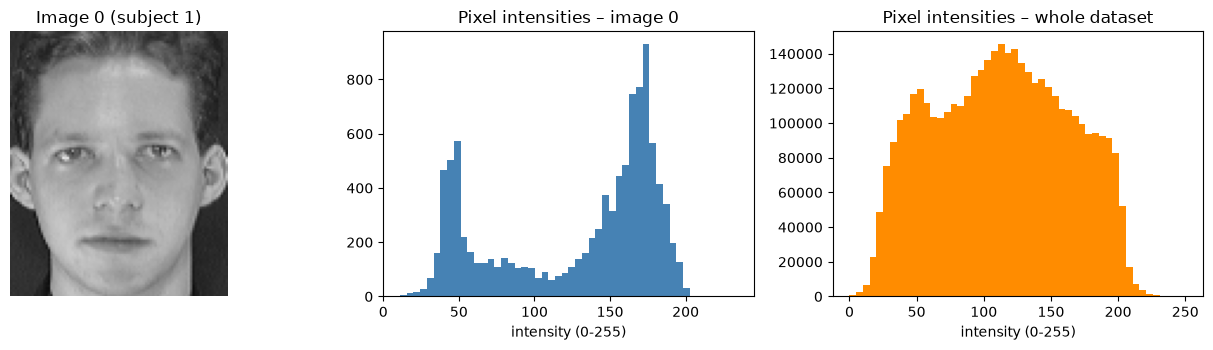

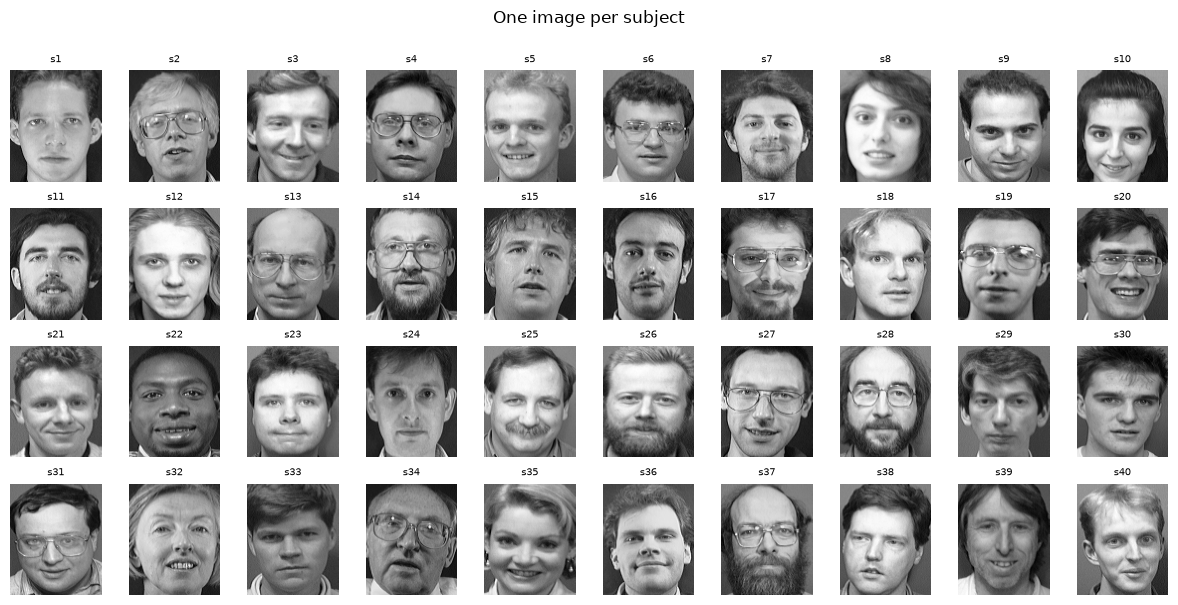

In [12]:
im0 = imgs[0]
print("dtype            :", im0.dtype)
print("shape (H, W)     :", im0.shape)
print("min / max        :", im0.min(), "/", im0.max())
print("mean / std       :", round(im0.mean(), 2), "/", round(im0.std(), 2))
print("\nTop-left 8x8 block of pixel matrix of image 0:\n", im0[:8, :8])

all_pix = np.concatenate([im.ravel() for im in imgs])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].imshow(im0, cmap="gray", vmin=0, vmax=255); ax[0].set_title(f"Image 0 (subject {subjects[y[0]]})"); ax[0].axis("off")
ax[1].hist(im0.ravel(), bins=50, color="steelblue"); ax[1].set_title("Pixel intensities – image 0")
ax[2].hist(all_pix, bins=50, color="darkorange"); ax[2].set_title("Pixel intensities – whole dataset")
for a in ax[1:]: a.set_xlabel("intensity (0-255)")
plt.tight_layout(); plt.savefig("figures/01_pixel_inspection.png", bbox_inches="tight"); plt.show()

# one sample per subject
cols = 10; rows = int(np.ceil(n_subjects / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.2, rows * 1.5))
first_idx = [np.where(y == k)[0][0] for k in range(n_subjects)]
for a in axes.ravel(): a.axis("off")
for a, i in zip(axes.ravel(), first_idx):
    a.imshow(imgs[i], cmap="gray"); a.set_title(f"s{subjects[y[i]]}", fontsize=7)
plt.suptitle("One image per subject", y=1.0); plt.tight_layout()
plt.savefig("figures/02_subjects_overview.png", bbox_inches="tight"); plt.show()

### A3. Flatten into feature vectors and build the image matrix
Each $H\times W$ image becomes a row vector of length $D=H\cdot W$. Pixels are scaled to $[0,1]$. The full data matrix is $X\in\mathbb{R}^{N\times D}$ with label vector $y\in\mathbb{R}^N$.

In [13]:
X = np.stack([im.reshape(-1) for im in imgs]).astype(np.float64) / 255.0
N, D = X.shape
print("Image matrix X :", X.shape, " (N images x D pixels)")
print("Label vector y :", y.shape)
print("Value range    :", X.min(), "-", X.max())

Image matrix X : (400, 10304)  (N images x D pixels)
Label vector y : (400,)
Value range    : 0.0 - 0.984313725490196


### A4. Reproducible, stratified train/test split
For **every subject**, images are shuffled with a fixed seed; 20 % (2 of 10) go to the test set and the rest to the training set, so every subject appears in both sets. The split is written with NumPy only.

In [14]:
def stratified_split(y, test_frac=0.2, seed=SEED):
    r = np.random.default_rng(seed)
    tr, te = [], []
    for k in np.unique(y):
        idx = r.permutation(np.where(y == k)[0])
        n_te = max(1, int(round(test_frac * len(idx))))
        te += list(idx[:n_te]); tr += list(idx[n_te:])
    return np.sort(tr), np.sort(te)

tr_idx, te_idx = stratified_split(y)
X_train, y_train = X[tr_idx], y[tr_idx]
X_test,  y_test  = X[te_idx], y[te_idx]

assert set(np.unique(y_train)) == set(np.unique(y_test)) == set(np.unique(y))
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print("Subjects in train:", len(np.unique(y_train)), "| subjects in test:", len(np.unique(y_test)))
print("Train images per subject:", np.unique(np.bincount(y_train)), "| Test images per subject:", np.unique(np.bincount(y_test)))

Train: (320, 10304)   Test: (80, 10304)
Subjects in train: 40 | subjects in test: 40
Train images per subject: [8] | Test images per subject: [2]


## Part B – PCA, Eigenfaces and Compression
### B1. Mean face and centering
$\mu = \frac1N\sum_i x_i$,  $A = X_{train}-\mu$. **Only the training set** is used to compute $\mu$ and the principal directions; test images are later centred with the *same* $\mu$.

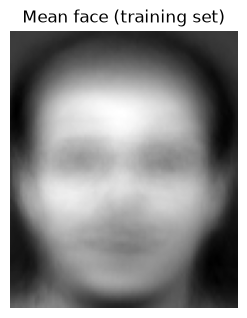

Column means of A ~ 0 : True


In [15]:
mean_face = X_train.mean(axis=0)
A = X_train - mean_face            # centered training data  (n x D)
n = A.shape[0]

plt.figure(figsize=(3, 3.6)); plt.imshow(mean_face.reshape(H, W), cmap="gray")
plt.title("Mean face (training set)"); plt.axis("off")
plt.savefig("figures/03_mean_face.png", bbox_inches="tight"); plt.show()
print("Column means of A ~ 0 :", np.allclose(A.mean(axis=0), 0))

### B2. Principal directions: covariance / eigendecomposition vs SVD
**Method 1 – Covariance eigendecomposition.** The full covariance $C=\frac{1}{n-1}A^\top A$ is $D\times D$ ($10304^2$ ≈ 850 MB), which is wasteful when $n\ll D$. Instead we use the classic *eigenface trick* of Turk & Pentland: eigendecompose the small $n\times n$ matrix $L=\frac{1}{n-1}AA^\top$. If $Lv=\lambda v$ then $u=A^\top v$ (normalised) is an eigenvector of $C$ with the **same eigenvalue** $\lambda$. This is mathematically exact for the non-zero eigenvalues.

**Method 2 – SVD.** $A=U\Sigma V^\top$; columns of $V$ are the principal directions and $\lambda_i=\sigma_i^2/(n-1)$.

In [16]:
# ---------- Method 1: eigendecomposition of the (n x n) Gram/covariance matrix ----------
t0 = time.perf_counter()
L = (A @ A.T) / (n - 1)
eigvals_cov, V = np.linalg.eigh(L)                 # ascending order
order = np.argsort(eigvals_cov)[::-1]
eigvals_cov, V = eigvals_cov[order], V[:, order]
keep = eigvals_cov > 1e-10 * eigvals_cov[0]        # drop numerically-zero eigenvalues (rank <= n-1)
eigvals_cov, V = eigvals_cov[keep], V[:, keep]
U_cov = A.T @ V                                    # map back to pixel space  (D x r)
U_cov /= np.linalg.norm(U_cov, axis=0, keepdims=True)
t_cov = time.perf_counter() - t0

# ---------- Method 2: SVD of the centered data ----------
t0 = time.perf_counter()
Usvd, S, Vt = np.linalg.svd(A, full_matrices=False)
t_svd = time.perf_counter() - t0
eigvals_svd = S**2 / (n - 1)
W_svd = Vt.T                                       # D x min(n, D)

r = len(eigvals_cov)
print(f"Rank of centered data (non-zero eigenvalues): {r}  (<= n-1 = {n-1})")
print(f"Time  covariance/eigh : {t_cov:.3f}s     SVD : {t_svd:.3f}s")

Rank of centered data (non-zero eigenvalues): 319  (<= n-1 = 319)
Time  covariance/eigh : 0.381s     SVD : 0.920s


Max |eigenvalue difference|                 : 1.279e-13
Min |cos| between matching components (top 50): 1.000000
Mean |cos| over all 319 components              : 1.000000
Max ||C u - lambda u|| for first 10 eigenvectors : 3.889e-14
Orthonormality  U^T U ~ I (cov): True | (SVD): True


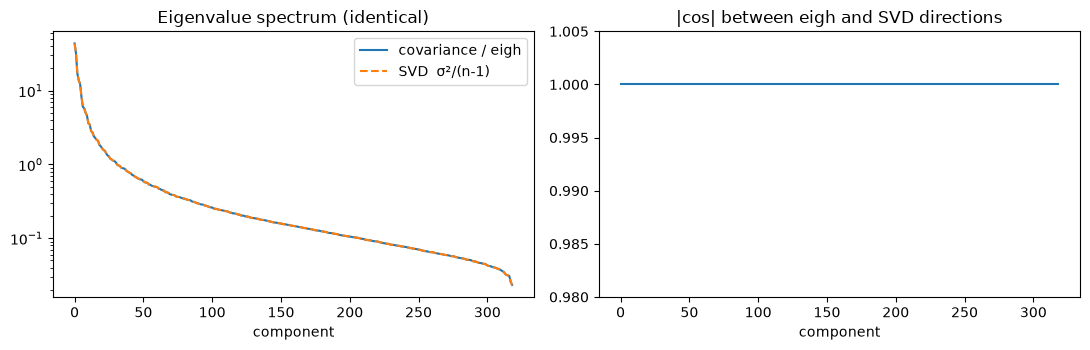

In [17]:
# ---------- Compare the two approaches ----------
eig_diff = np.max(np.abs(eigvals_cov - eigvals_svd[:r]))
cos = np.abs(np.sum(U_cov * W_svd[:, :r], axis=0))             # |cos angle| per component (sign is arbitrary)
top = 50
print(f"Max |eigenvalue difference|                 : {eig_diff:.3e}")
print(f"Min |cos| between matching components (top {top}): {cos[:top].min():.6f}")
print(f"Mean |cos| over all {r} components              : {cos.mean():.6f}")

# direct check that U_cov are true eigenvectors of the full covariance C = A^T A/(n-1),
# without ever building the D x D matrix:  C u = A^T (A u)/(n-1)
chk = 10
Cu = A.T @ (A @ U_cov[:, :chk]) / (n - 1)
resid = np.linalg.norm(Cu - U_cov[:, :chk] * eigvals_cov[:chk], axis=0).max()
print(f"Max ||C u - lambda u|| for first {chk} eigenvectors : {resid:.3e}")
print("Orthonormality  U^T U ~ I (cov):", np.allclose(U_cov.T @ U_cov, np.eye(r), atol=1e-6),
      "| (SVD):", np.allclose(W_svd[:, :r].T @ W_svd[:, :r], np.eye(r), atol=1e-6))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].semilogy(eigvals_cov, label="covariance / eigh"); ax[0].semilogy(eigvals_svd[:r], "--", label="SVD  σ²/(n-1)")
ax[0].set_title("Eigenvalue spectrum (identical)"); ax[0].set_xlabel("component"); ax[0].legend()
ax[1].plot(cos); ax[1].set_ylim(0.98 if cos.min() > 0.98 else 0, 1.005)
ax[1].set_title("|cos| between eigh and SVD directions"); ax[1].set_xlabel("component")
plt.tight_layout(); plt.savefig("figures/04_eigh_vs_svd.png", bbox_inches="tight"); plt.show()

**Observation.** Eigenvalues agree to machine precision and the principal directions coincide up to sign (|cos| ≈ 1). Any tiny deviation for the very last components is expected: their eigenvalues are almost equal/near zero, so their directions are numerically ill-defined. SVD is the more numerically stable route (it never squares the data matrix), while the Gram-matrix route is cheap when $n \ll D$. Below, we use the **SVD** basis.

In [18]:
W_all = W_svd[:, :r]            # D x r principal directions (eigenfaces)
eigvals = eigvals_svd[:r]

### B3. Explained variance and choosing the number of components
$\text{EVR}_i=\lambda_i/\sum_j\lambda_j$. We keep the **smallest $k$ with cumulative variance ≥ 90 %**.

Components for 90% variance: k90 = 100
(for reference)  95%: 164   99%: 267   of max 319
Variance of 1st / 2nd / 3rd component: 0.177 / 0.130 / 0.069
Dimensionality reduction: 10304 -> 100  (103x fewer features)


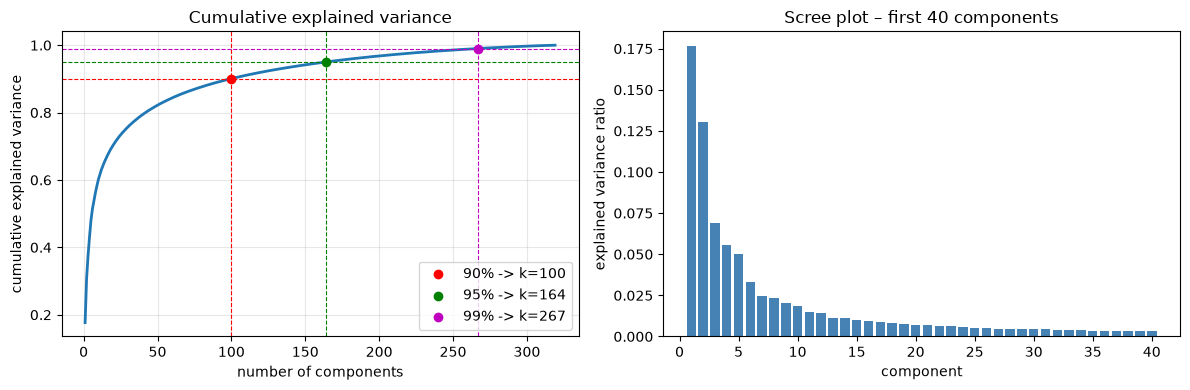

In [19]:
evr = eigvals / eigvals.sum()
cum_evr = np.cumsum(evr)
k90 = int(np.searchsorted(cum_evr, 0.90) + 1)
k95 = int(np.searchsorted(cum_evr, 0.95) + 1)
k99 = int(np.searchsorted(cum_evr, 0.99) + 1)
print(f"Components for 90% variance: k90 = {k90}")
print(f"(for reference)  95%: {k95}   99%: {k99}   of max {r}")
print(f"Variance of 1st / 2nd / 3rd component: {evr[0]:.3f} / {evr[1]:.3f} / {evr[2]:.3f}")
print(f"Dimensionality reduction: {D} -> {k90}  ({D/k90:.0f}x fewer features)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(1, r + 1), cum_evr, lw=2)
for thr, kk, c in [(0.90, k90, "r"), (0.95, k95, "g"), (0.99, k99, "m")]:
    ax[0].axhline(thr, color=c, ls="--", lw=0.8); ax[0].axvline(kk, color=c, ls="--", lw=0.8)
    ax[0].scatter([kk], [thr], color=c, zorder=5, label=f"{int(thr*100)}% -> k={kk}")
ax[0].set_xlabel("number of components"); ax[0].set_ylabel("cumulative explained variance")
ax[0].set_title("Cumulative explained variance"); ax[0].legend(loc="lower right"); ax[0].grid(alpha=.3)
ax[1].bar(np.arange(1, 41), evr[:40], color="steelblue")
ax[1].set_title("Scree plot – first 40 components"); ax[1].set_xlabel("component"); ax[1].set_ylabel("explained variance ratio")
plt.tight_layout(); plt.savefig("figures/05_explained_variance.png", bbox_inches="tight"); plt.show()

### B4. Eigenfaces – principal components reshaped to images

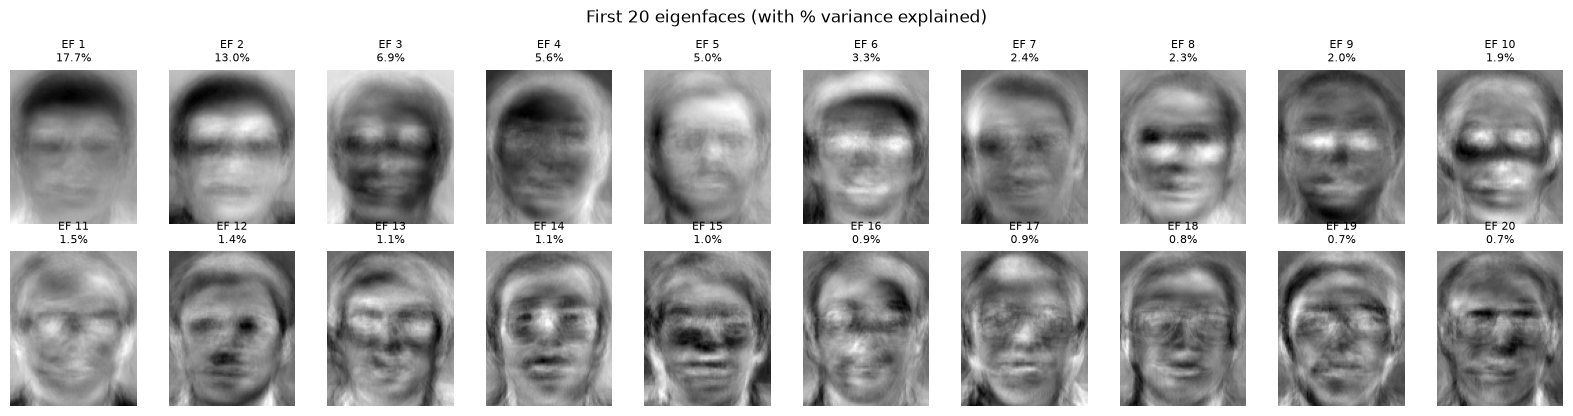

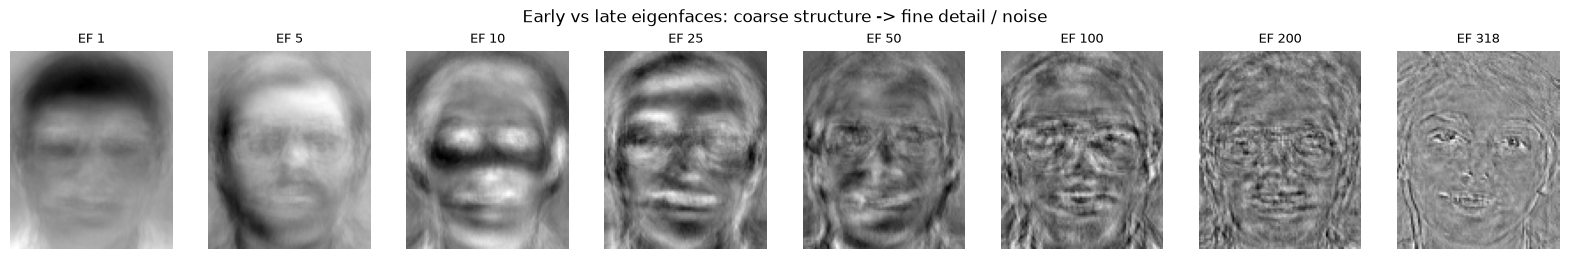

In [20]:
n_show = 20
fig, axes = plt.subplots(2, 10, figsize=(16, 4.2))
for i, a in enumerate(axes.ravel()[:n_show]):
    ef = W_all[:, i].reshape(H, W)
    a.imshow(ef, cmap="gray"); a.set_title(f"EF {i+1}\n{evr[i]*100:.1f}%", fontsize=8); a.axis("off")
plt.suptitle("First 20 eigenfaces (with % variance explained)")
plt.tight_layout(); plt.savefig("figures/06_eigenfaces.png", bbox_inches="tight"); plt.show()

# a few later eigenfaces to see the move from global structure to fine detail
idxs = [0, 4, 9, 24, 49, min(99, r-1), min(199, r-1), r-2]
fig, axes = plt.subplots(1, len(idxs), figsize=(2*len(idxs), 2.6))
for a, i in zip(axes, idxs):
    a.imshow(W_all[:, i].reshape(H, W), cmap="gray"); a.set_title(f"EF {i+1}", fontsize=9); a.axis("off")
plt.suptitle("Early vs late eigenfaces: coarse structure -> fine detail / noise")
plt.tight_layout(); plt.savefig("figures/07_eigenfaces_early_vs_late.png", bbox_inches="tight"); plt.show()

### B5. Projection to PCA space and stored reduced representation
$z = W_k^\top (x-\mu)$. Both train and test images are projected with the **training** mean and the **training** eigenfaces.

In [21]:
def project(Xs, k):
    return (Xs - mean_face) @ W_all[:, :k]

def reconstruct(Z):
    k = Z.shape[1]
    return Z @ W_all[:, :k].T + mean_face

Z_train = project(X_train, k90)
Z_test  = project(X_test,  k90)
print("Reduced train:", Z_train.shape, " reduced test:", Z_test.shape)

# store the reduced representation + what is needed to reconstruct it
np.savez_compressed("results/pca_representation.npz",
                    Z_train=Z_train, Z_test=Z_test, y_train=y_train, y_test=y_test,
                    mean_face=mean_face, components=W_all[:, :k90], eigenvalues=eigvals[:k90])
print("Saved -> results/pca_representation.npz")

Reduced train: (320, 100)  reduced test: (80, 100)
Saved -> results/pca_representation.npz


### B6. Reconstruction quality and storage

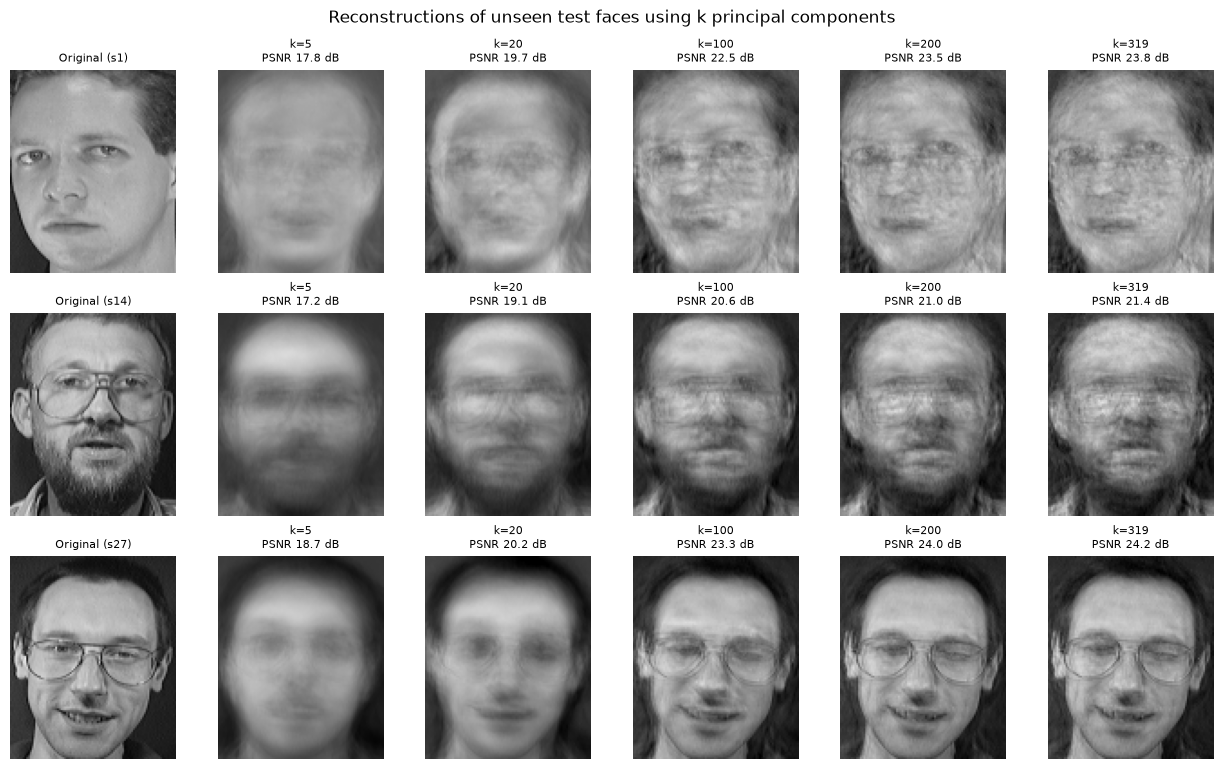

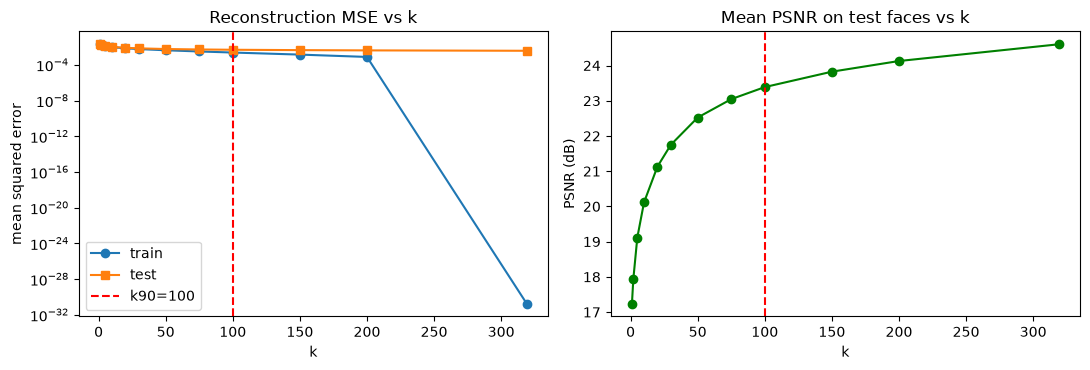

  k  MSE_train  MSE_test  PSNR_test_dB
  1    0.01966   0.01982      17.24254
  2    0.01654   0.01690      17.92597
  5    0.01237   0.01272      19.11695
 10    0.00951   0.01009      20.11475
 20    0.00708   0.00801      21.13049
 30    0.00579   0.00698      21.75030
 50    0.00425   0.00586      22.52323
 75    0.00312   0.00522      23.04500
100    0.00237   0.00483      23.38753
150    0.00139   0.00440      23.82471
200    0.00076   0.00412      24.12741
319    0.00000   0.00373      24.60212


In [22]:
def mse(a, b): return np.mean((a - b) ** 2, axis=1)
def psnr(a, b): return 10 * np.log10(1.0 / np.maximum(mse(a, b), 1e-12))

ks_show = [5, 20, k90, 2 * k90, r]
ks_show = sorted(set(min(k, r) for k in ks_show))
sample_ids = [0, len(X_test) // 3, 2 * len(X_test) // 3]     # three test faces

fig, axes = plt.subplots(len(sample_ids), len(ks_show) + 1, figsize=(2.1 * (len(ks_show) + 1), 2.6 * len(sample_ids)))
for row, s in enumerate(sample_ids):
    axes[row, 0].imshow(X_test[s].reshape(H, W), cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original (s{subjects[y_test[s]]})", fontsize=8); axes[row, 0].axis("off")
    for col, k in enumerate(ks_show, start=1):
        rec = reconstruct(project(X_test[s:s+1], k))[0]
        axes[row, col].imshow(np.clip(rec, 0, 1).reshape(H, W), cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(f"k={k}\nPSNR {psnr(X_test[s:s+1], rec[None])[0]:.1f} dB", fontsize=8)
        axes[row, col].axis("off")
plt.suptitle("Reconstructions of unseen test faces using k principal components")
plt.tight_layout(); plt.savefig("figures/08_reconstructions.png", bbox_inches="tight"); plt.show()

# error versus k
ks = sorted(set([1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, r]) | {k90})
ks = [k for k in ks if k <= r]
mse_te, mse_tr, psnr_te = [], [], []
for k in ks:
    rt = reconstruct(project(X_test, k)); rr = reconstruct(project(X_train, k))
    mse_te.append(mse(X_test, rt).mean()); mse_tr.append(mse(X_train, rr).mean()); psnr_te.append(psnr(X_test, rt).mean())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ks, mse_tr, "o-", label="train"); ax[0].plot(ks, mse_te, "s-", label="test")
ax[0].axvline(k90, color="r", ls="--", label=f"k90={k90}"); ax[0].set_yscale("log")
ax[0].set_xlabel("k"); ax[0].set_ylabel("mean squared error"); ax[0].set_title("Reconstruction MSE vs k"); ax[0].legend()
ax[1].plot(ks, psnr_te, "o-", color="green"); ax[1].axvline(k90, color="r", ls="--")
ax[1].set_xlabel("k"); ax[1].set_ylabel("PSNR (dB)"); ax[1].set_title("Mean PSNR on test faces vs k")
plt.tight_layout(); plt.savefig("figures/09_reconstruction_error.png", bbox_inches="tight"); plt.show()

recon_df = pd.DataFrame({"k": ks, "MSE_train": mse_tr, "MSE_test": mse_te, "PSNR_test_dB": psnr_te})
recon_df.to_csv("results/reconstruction_error.csv", index=False)
print(recon_df.round(5).to_string(index=False))

In [23]:
# ---------- storage comparison ----------
# Original: n x D pixel matrix.      PCA: scores (n x k) + eigenfaces (D x k) + mean face (D)
def storage_floats(n_img, k, D=D):
    return n_img * k + D * k + D

orig_f64   = n * D * 8                       # float64 pixels
orig_u8    = n * D * 1                       # raw 8-bit pixels (how the files really are stored)
pca_f64    = storage_floats(n, k90) * 8
scores_only = n * k90 * 8                    # per-image cost once the shared basis is amortised

rows = [
    ["Original pixels, float64", f"{n} x {D}", orig_f64 / 1e6, 1.0],
    ["Original pixels, uint8",   f"{n} x {D}", orig_u8 / 1e6, orig_f64 / orig_u8],
    [f"PCA k={k90}: scores + eigenfaces + mean (float64)", f"{n} x {k90} (+{D}x{k90}+{D})", pca_f64 / 1e6, orig_f64 / pca_f64],
    [f"PCA k={k90}: scores only (basis shared)", f"{n} x {k90}", scores_only / 1e6, orig_f64 / scores_only],
]
storage_df = pd.DataFrame(rows, columns=["Representation", "Stored arrays", "Size (MB)", "Compression vs float64 pixels"])
storage_df.to_csv("results/storage_comparison.csv", index=False)
print(storage_df.round(3).to_string(index=False))
print(f"\nPer-image cost: {D} values (pixels)  ->  {k90} values (PCA scores) = {D/k90:.0f}x smaller")
print(f"Break-even: the eigenface basis (D*k) is paid once, so compression improves as more faces are stored.")
n_big = 10_000
print(f"e.g. for {n_big} faces: pixels {n_big*D*8/1e6:.0f} MB  vs  PCA {storage_floats(n_big, k90)*8/1e6:.1f} MB  ({n_big*D/storage_floats(n_big, k90):.0f}x)")

                                 Representation                Stored arrays  Size (MB)  Compression vs float64 pixels
                       Original pixels, float64                  320 x 10304     26.378                          1.000
                         Original pixels, uint8                  320 x 10304      3.297                          8.000
PCA k=100: scores + eigenfaces + mean (float64) 320 x 100 (+10304x100+10304)      8.582                          3.074
          PCA k=100: scores only (basis shared)                    320 x 100      0.256                        103.040

Per-image cost: 10304 values (pixels)  ->  100 values (PCA scores) = 103x smaller
Break-even: the eigenface basis (D*k) is paid once, so compression improves as more faces are stored.
e.g. for 10000 faces: pixels 824 MB  vs  PCA 16.3 MB  (50x)


**Observation.** With roughly `k90` components the faces are already clearly recognisable, and the per-image cost falls from 10 304 numbers to `k90` numbers. The eigenface basis is a fixed one-off cost, so the saving grows with the number of stored faces. Reconstruction error drops quickly for the first tens of components and then flattens: later components mostly carry fine texture / noise.

## Part C – Recognition in PCA space
### C1. Nearest-neighbour matching (similarity-based baseline)
For each test image: centre with the training mean → project onto the eigenfaces → find the **closest stored training face** → predict that face's subject. Distances are implemented in NumPy (Euclidean; cosine is added for comparison).

In [24]:
def pairwise_sq_euclid(P, Q):
    d = (P**2).sum(1)[:, None] + (Q**2).sum(1)[None, :] - 2 * P @ Q.T
    return np.maximum(d, 0)

def pairwise_cosine(P, Q):
    Pn = P / np.linalg.norm(P, axis=1, keepdims=True); Qn = Q / np.linalg.norm(Q, axis=1, keepdims=True)
    return 1 - Pn @ Qn.T

def nn_match(Ztr, ytr, Zte, metric="euclidean"):
    Dm = np.sqrt(pairwise_sq_euclid(Zte, Ztr)) if metric == "euclidean" else pairwise_cosine(Zte, Ztr)
    idx = Dm.argmin(axis=1)
    return ytr[idx], idx, Dm[np.arange(len(Zte)), idx]

# --- PCA-space recognition (k = k90) ---
t0 = time.perf_counter()
pred_pca, nn_idx_pca, nn_dist_pca = nn_match(Z_train, y_train, Z_test, "euclidean")
t_pca = time.perf_counter() - t0
acc_pca = (pred_pca == y_test).mean()

pred_pca_cos, _, _ = nn_match(Z_train, y_train, Z_test, "cosine")
acc_pca_cos = (pred_pca_cos == y_test).mean()

# --- Raw pixel recognition (D = 10304) ---
t0 = time.perf_counter()
pred_raw, nn_idx_raw, nn_dist_raw = nn_match(X_train, y_train, X_test, "euclidean")
t_raw = time.perf_counter() - t0
acc_raw = (pred_raw == y_test).mean()

print(f"{'Representation':32s} {'dims':>6s} {'accuracy':>9s} {'match time (s)':>15s}")
print(f"{'Raw pixels, Euclidean':32s} {D:6d} {acc_raw:9.4f} {t_raw:15.4f}")
print(f"{f'PCA k={k90}, Euclidean':32s} {k90:6d} {acc_pca:9.4f} {t_pca:15.4f}")
print(f"{f'PCA k={k90}, cosine':32s} {k90:6d} {acc_pca_cos:9.4f}")
print(f"\nCorrect: {(pred_pca == y_test).sum()}/{len(y_test)} (PCA)   {(pred_raw == y_test).sum()}/{len(y_test)} (raw)")

Representation                     dims  accuracy  match time (s)
Raw pixels, Euclidean             10304    0.9625          0.2604
PCA k=100, Euclidean                100    0.9625          0.0054
PCA k=100, cosine                   100    0.9625

Correct: 77/80 (PCA)   77/80 (raw)


### C2. Correct and incorrect matches

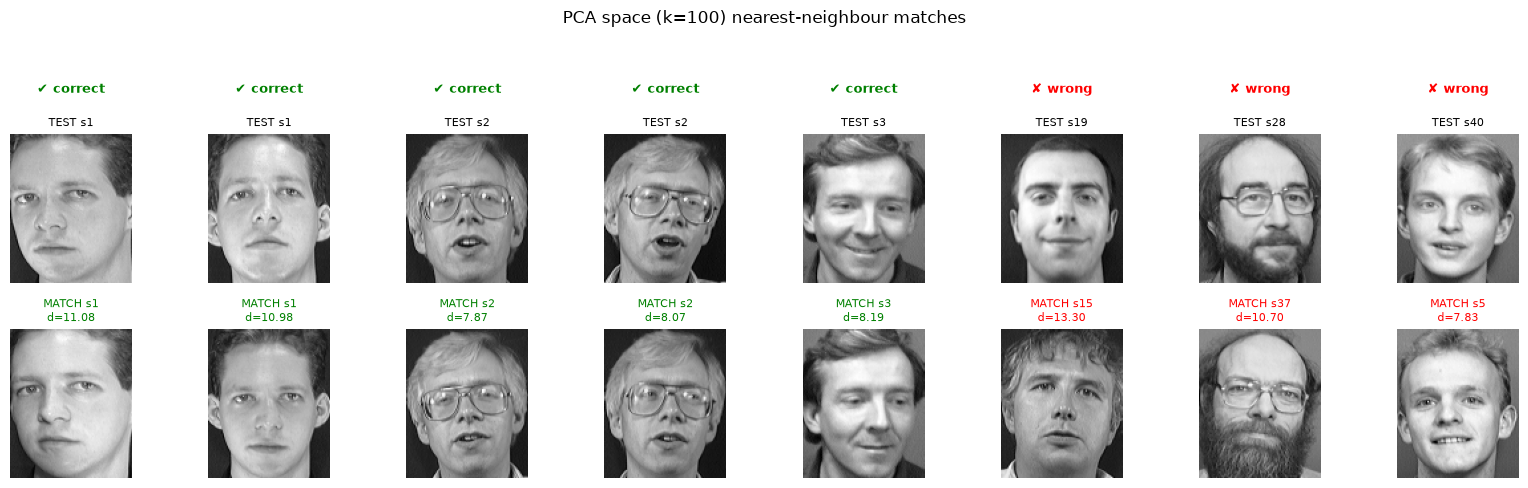

Test images where raw and PCA predictions differ: []
Misclassified test images (PCA): [(37, 'true s19', 'pred s15'), (55, 'true s28', 'pred s37'), (79, 'true s40', 'pred s5')]


In [25]:
def show_matches(pred, nn_idx, dists, title, fname, n_each=5):
    correct = np.where(pred == y_test)[0]; wrong = np.where(pred != y_test)[0]
    sel = [(i, True) for i in correct[:n_each]] + [(i, False) for i in wrong[:n_each]]
    if not sel:
        print("nothing to show"); return
    fig, axes = plt.subplots(2, len(sel), figsize=(2.0 * len(sel), 4.6), squeeze=False)
    for c, (i, ok) in enumerate(sel):
        axes[0, c].imshow(X_test[i].reshape(H, W), cmap="gray")
        axes[0, c].set_title(f"TEST s{subjects[y_test[i]]}", fontsize=8)
        axes[1, c].imshow(X_train[nn_idx[i]].reshape(H, W), cmap="gray")
        axes[1, c].set_title(f"MATCH s{subjects[pred[i]]}\nd={dists[i]:.2f}", fontsize=8, color="green" if ok else "red")
        for a in axes[:, c]:
            a.axis("off")
            for sp in a.spines.values(): sp.set_visible(False)
        axes[0, c].text(0.5, 1.28, "✔ correct" if ok else "✘ wrong", transform=axes[0, c].transAxes,
                        ha="center", fontsize=9, color="green" if ok else "red", fontweight="bold")
    plt.suptitle(title, y=1.05); plt.tight_layout(); plt.savefig(fname, bbox_inches="tight"); plt.show()

show_matches(pred_pca, nn_idx_pca, nn_dist_pca, f"PCA space (k={k90}) nearest-neighbour matches", "figures/10_matches_pca.png")
if (pred_raw != y_test).any() or (pred_pca != y_test).any():
    disagree = np.where(pred_raw != pred_pca)[0]
    print("Test images where raw and PCA predictions differ:", disagree.tolist())
print("Misclassified test images (PCA):", [(int(i), f"true s{subjects[y_test[i]]}", f"pred s{subjects[pred_pca[i]]}") for i in np.where(pred_pca != y_test)[0]])

### C3. Accuracy as a function of the number of PCA components, vs raw pixels

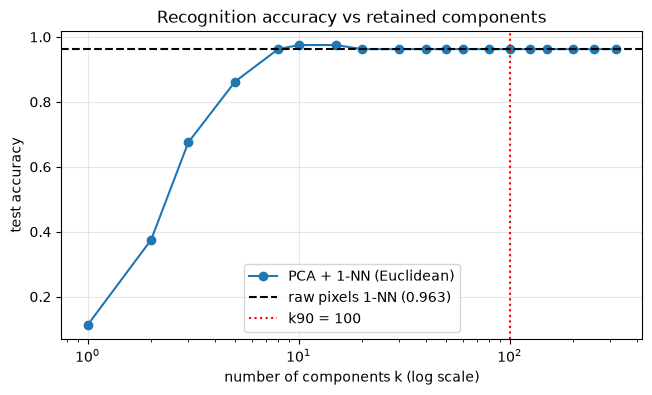

  k  1-NN accuracy
  1         0.1125
  2         0.3750
  3         0.6750
  5         0.8625
  8         0.9625
 10         0.9750
 15         0.9750
 20         0.9625
 30         0.9625
 40         0.9625
 50         0.9625
 60         0.9625
 80         0.9625
100         0.9625
125         0.9625
150         0.9625
200         0.9625
250         0.9625
319         0.9625


In [26]:
K_max = r
Ztr_full = project(X_train, K_max); Zte_full = project(X_test, K_max)
ks_c = sorted(set([1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 50, 60, 80, 100, 125, 150, 200, 250, r]) | {k90})
ks_c = [k for k in ks_c if k <= r]
acc_k = []
for k in ks_c:
    p, _, _ = nn_match(Ztr_full[:, :k], y_train, Zte_full[:, :k], "euclidean")
    acc_k.append((p == y_test).mean())

plt.figure(figsize=(7.5, 4))
plt.plot(ks_c, acc_k, "o-", label="PCA + 1-NN (Euclidean)")
plt.axhline(acc_raw, color="k", ls="--", label=f"raw pixels 1-NN ({acc_raw:.3f})")
plt.axvline(k90, color="r", ls=":", label=f"k90 = {k90}")
plt.xscale("log"); plt.xlabel("number of components k (log scale)"); plt.ylabel("test accuracy")
plt.title("Recognition accuracy vs retained components"); plt.grid(alpha=.3); plt.legend()
plt.savefig("figures/11_accuracy_vs_k_nn.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"k": ks_c, "nn_accuracy": acc_k}).to_csv("results/nn_accuracy_vs_k.csv", index=False)
print(pd.DataFrame({"k": ks_c, "1-NN accuracy": np.round(acc_k, 4)}).to_string(index=False))

### C4. Robustness check – repeated random splits
With only 80 test images, one split changes accuracy in steps of 1.25 %. To check that conclusions do not hinge on one split, the baseline comparison is repeated over 10 different seeded splits (PCA is refit on each training set).

In [27]:
reps = []
for sd in range(10):
    tr_i, te_i = stratified_split(y, 0.2, seed=1000 + sd)
    Xa, ya, Xb, yb = X[tr_i], y[tr_i], X[te_i], y[te_i]
    mu = Xa.mean(0); Ac = Xa - mu
    _, s_, Vt_ = np.linalg.svd(Ac, full_matrices=False)
    ev = s_**2 / (len(Xa) - 1); cv = np.cumsum(ev) / ev.sum()
    kk = int(np.searchsorted(cv, 0.90) + 1)
    Wk = Vt_[:kk].T
    p_pca, _, _ = nn_match(Ac @ Wk, ya, (Xb - mu) @ Wk)
    p_raw, _, _ = nn_match(Xa, ya, Xb)
    reps.append({"seed": 1000 + sd, "k90": kk, "raw_acc": (p_raw == yb).mean(), "pca_acc": (p_pca == yb).mean()})
reps_df = pd.DataFrame(reps)
print(reps_df.round(4).to_string(index=False))
print(f"\nRaw pixels 1-NN : {reps_df.raw_acc.mean():.4f} ± {reps_df.raw_acc.std():.4f}")
print(f"PCA(90%) 1-NN   : {reps_df.pca_acc.mean():.4f} ± {reps_df.pca_acc.std():.4f}   (mean k90 = {reps_df.k90.mean():.1f})")
reps_df.to_csv("results/repeated_split_baselines.csv", index=False)

 seed  k90  raw_acc  pca_acc
 1000   98   0.9750   0.9750
 1001   98   0.9750   0.9625
 1002   99   0.9750   0.9875
 1003   99   0.9875   0.9875
 1004   99   0.9625   0.9625
 1005   98   0.9875   0.9875
 1006   99   0.9875   1.0000
 1007   97   0.9625   0.9750
 1008   99   1.0000   1.0000
 1009   99   0.9750   0.9750

Raw pixels 1-NN : 0.9788 ± 0.0119
PCA(90%) 1-NN   : 0.9812 ± 0.0135   (mean k90 = 98.5)


## Part D – Traditional machine learning on PCA features
Scikit-learn is used **only here**. PCA features come from our NumPy implementation (fitted on the training set only).

Classifiers: **k-NN, Logistic Regression, linear SVM, RBF SVM**. For every model and every number of components $k$ we tune hyper-parameters (including whether to standardise the PCA scores) with **stratified 4-fold cross-validation on the training set**. The best configuration is then chosen by **CV score**, not by test accuracy, so the test set stays an honest final check.

In [28]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

scalers = ["passthrough", StandardScaler()]
model_specs = {
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [1, 3, 5], "clf__weights": ["uniform", "distance"], "scaler": scalers}),
    "Logistic Regression": (LogisticRegression(max_iter=5000),
            {"clf__C": [0.01, 0.1, 1, 10, 100], "scaler": scalers}),
    "SVM (linear)": (SVC(kernel="linear"),
            {"clf__C": [0.01, 0.1, 1, 10], "scaler": scalers}),
    "SVM (RBF)": (SVC(kernel="rbf"),
            {"clf__C": [1, 10, 100], "clf__gamma": ["scale", "auto"], "scaler": scalers}),
}
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
ks_d = sorted(set([10, 20, 30, 40, 60, 80, 120, 160]) | {k90})
ks_d = [k for k in ks_d if k <= r]

records = []
t_all = time.perf_counter()
for k in ks_d:
    Ztr_k, Zte_k = Ztr_full[:, :k], Zte_full[:, :k]
    for name, (est, grid) in model_specs.items():
        pipe = Pipeline([("scaler", "passthrough"), ("clf", est)])
        t0 = time.perf_counter()
        gs = GridSearchCV(pipe, grid, cv=cv, n_jobs=-1, refit=True).fit(Ztr_k, y_train)
        fit_t = time.perf_counter() - t0
        sc = gs.best_params_["scaler"]
        params = {kk.replace("clf__", ""): v for kk, v in gs.best_params_.items() if kk != "scaler"}
        params["standardize"] = sc != "passthrough"
        records.append({"model": name, "k": k, "cv_acc": gs.best_score_,
                        "test_acc": (gs.predict(Zte_k) == y_test).mean(),
                        "best_params": params, "tune_time_s": fit_t, "_est": gs.best_estimator_})
print(f"Grid search finished in {time.perf_counter() - t_all:.1f}s")
res = pd.DataFrame(records)
res_show = res.drop(columns="_est")
res_show.to_csv("results/ml_all_configs.csv", index=False)
print(res_show.pivot(index="k", columns="model", values="test_acc").round(4).to_string())

Grid search finished in 22.1s
model     KNN  Logistic Regression  SVM (RBF)  SVM (linear)
k                                                          
10     0.9750               0.9625     0.9750         0.975
20     0.9625               0.9750     0.9750         0.975
30     0.9625               0.9750     0.9750         0.975
40     0.9625               0.9750     0.9625         0.975
60     0.9625               0.9750     0.9750         0.975
80     0.9625               0.9750     0.9750         0.975
100    0.9625               0.9750     0.9750         0.975
120    0.9625               0.9750     0.9750         0.975
160    0.9625               0.9750     0.9750         0.975


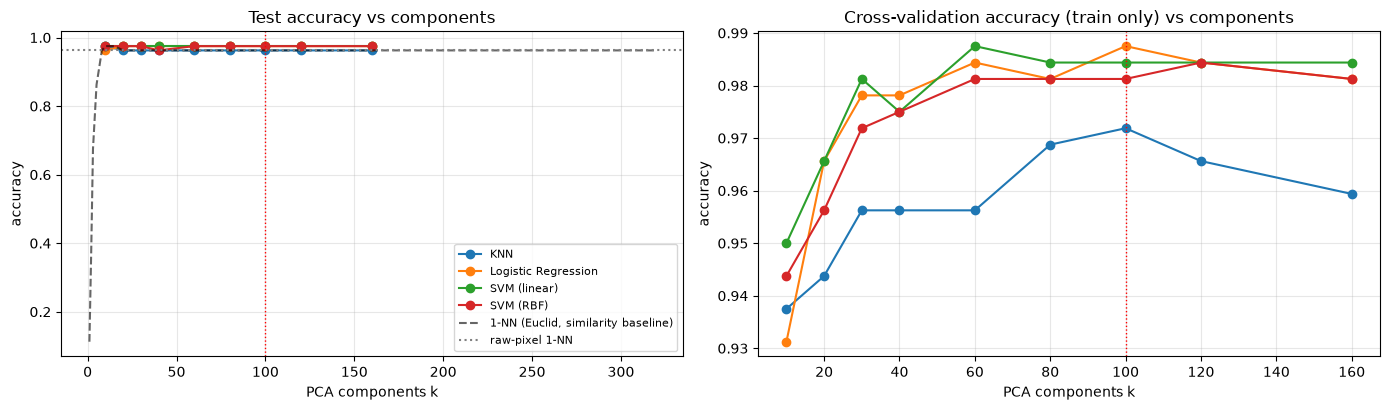

In [29]:
# Accuracy vs k for all models + similarity baselines
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for name in model_specs:
    sub = res[res.model == name]
    ax[0].plot(sub.k, sub.test_acc, "o-", label=name)
    ax[1].plot(sub.k, sub.cv_acc, "o-", label=name)
ax[0].plot(ks_c, acc_k, "k--", alpha=.6, label="1-NN (Euclid, similarity baseline)")
ax[0].axhline(acc_raw, color="gray", ls=":", label="raw-pixel 1-NN")
for a, t in zip(ax, ["Test accuracy vs components", "Cross-validation accuracy (train only) vs components"]):
    a.axvline(k90, color="r", ls=":", lw=1); a.set_xlabel("PCA components k"); a.set_ylabel("accuracy"); a.set_title(t); a.grid(alpha=.3)
ax[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("figures/12_ml_accuracy_vs_k.png", bbox_inches="tight"); plt.show()

### Model selection (by cross-validation score; ties → fewer components, i.e. more compact)

In [30]:
res["_rank"] = list(zip(-res.cv_acc.round(6), res.k))
best_rows = res.sort_values("_rank").groupby("model", sort=False).head(1).drop(columns="_rank")
overall_best = res.sort_values("_rank").iloc[0]

# ---------- final comparison table ----------
table = []
table.append({"Method": "Raw pixels + 1-NN (Euclidean)", "Features": D, "CV acc": np.nan, "Test acc": acc_raw, "Settings": "-"})
table.append({"Method": f"PCA(k90) + 1-NN (Euclidean)", "Features": k90, "CV acc": np.nan, "Test acc": acc_pca, "Settings": "similarity baseline"})
table.append({"Method": f"PCA(k90) + 1-NN (cosine)", "Features": k90, "CV acc": np.nan, "Test acc": acc_pca_cos, "Settings": "similarity baseline"})
for name in model_specs:
    row = res[(res.model == name) & (res.k == k90)].iloc[0]
    table.append({"Method": f"PCA(k90) + {name}", "Features": k90, "CV acc": row.cv_acc, "Test acc": row.test_acc, "Settings": str(row.best_params)})
for _, row in best_rows.iterrows():
    table.append({"Method": f"PCA(best k) + {row.model}", "Features": int(row.k), "CV acc": row.cv_acc, "Test acc": row.test_acc, "Settings": str(row.best_params)})
comparison = pd.DataFrame(table)
comparison.to_csv("results/ml_comparison_table.csv", index=False)
pd.set_option("display.max_colwidth", 90, "display.width", 200)
print(comparison.round(4).to_string(index=False))

print(f"\nBest by CV: {overall_best.model} with k={int(overall_best.k)}  "
      f"(CV {overall_best.cv_acc:.4f}, test {overall_best.test_acc:.4f})  params={overall_best.best_params}")

                           Method  Features  CV acc  Test acc                                                       Settings
    Raw pixels + 1-NN (Euclidean)     10304     NaN    0.9625                                                              -
      PCA(k90) + 1-NN (Euclidean)       100     NaN    0.9625                                            similarity baseline
         PCA(k90) + 1-NN (cosine)       100     NaN    0.9625                                            similarity baseline
                   PCA(k90) + KNN       100  0.9719    0.9625 {'n_neighbors': 1, 'weights': 'uniform', 'standardize': False}
   PCA(k90) + Logistic Regression       100  0.9875    0.9750                               {'C': 100, 'standardize': False}
          PCA(k90) + SVM (linear)       100  0.9844    0.9750                               {'C': 0.1, 'standardize': False}
             PCA(k90) + SVM (RBF)       100  0.9812    0.9750              {'C': 10, 'gamma': 'scale', 'standardize': False}


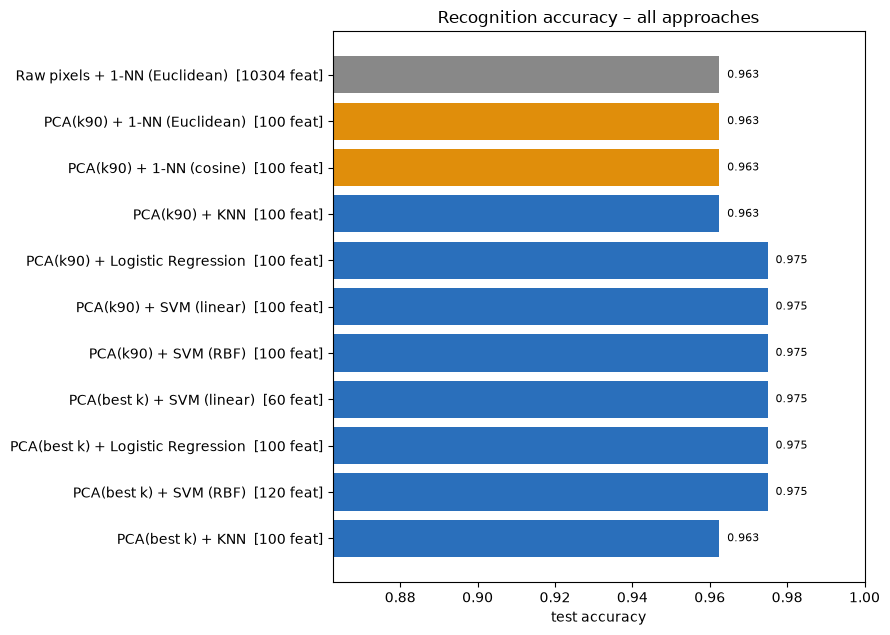

Selected model misclassifies 2 / 80 test images:
  test #37: true s19 -> predicted s11
  test #55: true s28 -> predicted s37


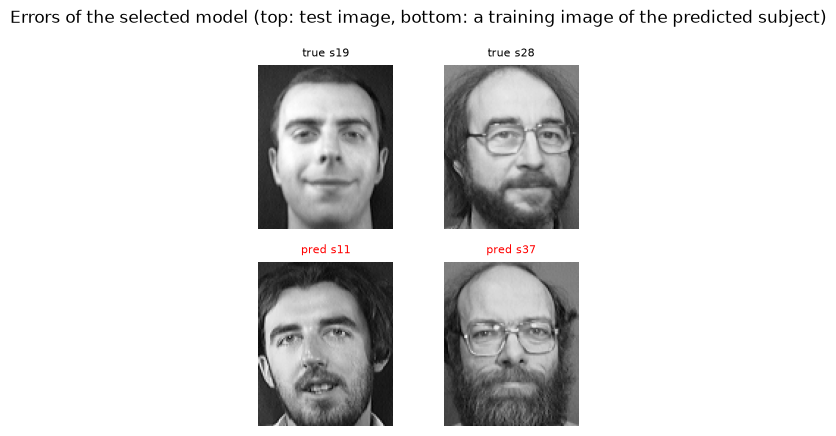

In [31]:
# Visual summary + errors of the selected model
fig, ax = plt.subplots(figsize=(9, 0.45 * len(comparison) + 1.5))
cmp_plot = comparison.iloc[::-1]
colors = ["#888" if "Raw" in m else ("#e08e0b" if "1-NN" in m else "#2a6fbb") for m in cmp_plot.Method]
ax.barh(cmp_plot.Method + "  [" + cmp_plot.Features.astype(str) + " feat]", cmp_plot["Test acc"], color=colors)
ax.set_xlim(max(0, comparison["Test acc"].min() - 0.1), 1.0); ax.set_xlabel("test accuracy")
for i, v in enumerate(cmp_plot["Test acc"]): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_title("Recognition accuracy – all approaches")
plt.tight_layout(); plt.savefig("figures/13_final_comparison.png", bbox_inches="tight"); plt.show()

best_est = overall_best["_est"]; kb = int(overall_best.k)
pred_best = best_est.predict(Zte_full[:, :kb])
wrong = np.where(pred_best != y_test)[0]
print(f"Selected model misclassifies {len(wrong)} / {len(y_test)} test images:")
for i in wrong:
    print(f"  test #{i}: true s{subjects[y_test[i]]} -> predicted s{subjects[pred_best[i]]}")

if len(wrong):
    m = min(len(wrong), 8)
    fig, axes = plt.subplots(2, m, figsize=(2 * m, 4.4), squeeze=False)
    for c, i in enumerate(wrong[:m]):
        axes[0, c].imshow(X_test[i].reshape(H, W), cmap="gray"); axes[0, c].set_title(f"true s{subjects[y_test[i]]}", fontsize=8)
        ex = X_train[y_train == pred_best[i]][0]
        axes[1, c].imshow(ex.reshape(H, W), cmap="gray"); axes[1, c].set_title(f"pred s{subjects[pred_best[i]]}", fontsize=8, color="red")
        axes[0, c].axis("off"); axes[1, c].axis("off")
    plt.suptitle("Errors of the selected model (top: test image, bottom: a training image of the predicted subject)")
    plt.tight_layout(); plt.savefig("figures/14_best_model_errors.png", bbox_inches="tight"); plt.show()

## Summary of results (auto-generated from this run)

In [32]:
best_tbl = best_rows.sort_values("cv_acc", ascending=False)
lines = []
lines.append(f"- Dataset: {N} images, {n_subjects} subjects, {H}x{W} px ({D} raw features). Train {len(X_train)} / Test {len(X_test)} (stratified, seed {SEED}).")
lines.append(f"- PCA: {k90} components keep >= 90% variance ({D/k90:.0f}x fewer features); 95% needs {k95}, 99% needs {k99}.")
lines.append(f"- Covariance (Gram trick) vs SVD: max eigenvalue difference {eig_diff:.2e}; min |cos| of top-{top} directions {cos[:top].min():.5f}.")
lines.append(f"- Storage (float64, {n} faces): pixels {orig_f64/1e6:.1f} MB -> PCA scores+basis {pca_f64/1e6:.2f} MB ({orig_f64/pca_f64:.1f}x); per-image {D} -> {k90} numbers.")
lines.append(f"- Reconstruction at k={k90}: mean test PSNR {recon_df.loc[recon_df.k == k90, 'PSNR_test_dB'].values[0]:.1f} dB.")
lines.append(f"- 1-NN accuracy: raw pixels {acc_raw:.4f} vs PCA(k={k90}) {acc_pca:.4f} (Euclidean), {acc_pca_cos:.4f} (cosine).")
lines.append(f"- Over 10 random splits: raw {reps_df.raw_acc.mean():.4f}±{reps_df.raw_acc.std():.4f}, PCA {reps_df.pca_acc.mean():.4f}±{reps_df.pca_acc.std():.4f}.")
lines.append(f"- Matching time (test set): raw {t_raw*1000:.1f} ms vs PCA {t_pca*1000:.1f} ms.")
for _, row in best_tbl.iterrows():
    lines.append(f"- {row.model}: best k={int(row.k)}, CV {row.cv_acc:.4f}, test {row.test_acc:.4f}, params {row.best_params}")
lines.append(f"- Selected overall (by CV, smallest k on ties): **{overall_best.model}, k={kb}**, test accuracy {overall_best.test_acc:.4f}.")
summary_md = "\n".join(lines)
print(summary_md)

def df_to_md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, rw in df.iterrows():
        out.append("| " + " | ".join(f"{v:.4f}" if isinstance(v, float) else str(v) for v in rw.values) + " |")
    return "\n".join(out)

with open("results/summary.md", "w", encoding="utf-8") as f:
    f.write("# Results summary\n\n" + summary_md + "\n\n## Comparison table\n\n" + df_to_md(comparison) + "\n")
print("\nSaved -> results/summary.md (paste into README), figures/*.png, results/*.csv")

- Dataset: 400 images, 40 subjects, 112x92 px (10304 raw features). Train 320 / Test 80 (stratified, seed 42).
- PCA: 100 components keep >= 90% variance (103x fewer features); 95% needs 164, 99% needs 267.
- Covariance (Gram trick) vs SVD: max eigenvalue difference 1.28e-13; min |cos| of top-50 directions 1.00000.
- Storage (float64, 320 faces): pixels 26.4 MB -> PCA scores+basis 8.58 MB (3.1x); per-image 10304 -> 100 numbers.
- Reconstruction at k=100: mean test PSNR 23.4 dB.
- 1-NN accuracy: raw pixels 0.9625 vs PCA(k=100) 0.9625 (Euclidean), 0.9625 (cosine).
- Over 10 random splits: raw 0.9788±0.0119, PCA 0.9812±0.0135.
- Matching time (test set): raw 260.4 ms vs PCA 5.4 ms.
- SVM (linear): best k=60, CV 0.9875, test 0.9750, params {'C': 0.1, 'standardize': False}
- Logistic Regression: best k=100, CV 0.9875, test 0.9750, params {'C': 100, 'standardize': False}
- SVM (RBF): best k=120, CV 0.9844, test 0.9750, params {'C': 10, 'gamma': 'scale', 'standardize': False}
- KNN: best k=10

## Observations and discussion
*(The numbers above are regenerated on each run; the points below describe the behaviour expected and typically seen on ORL – check them against your printed results and edit if your run differs.)*

1. **Dimensionality.** Faces are highly redundant: roughly a hundred principal components capture ≥ 90 % of the variance of 10 304 pixels. The first eigenfaces encode global illumination and face shape; later ones encode fine detail and noise.
2. **Covariance vs SVD.** Both give the same eigenvalues and directions (up to sign). The Gram-matrix trick makes the covariance route feasible when $n \ll D$; SVD is simpler and numerically more stable.
3. **Compression.** Per image the representation shrinks by ~$D/k$; the shared eigenface basis is a one-time cost, so savings grow with the number of faces. Reconstructions at `k90` stay clearly recognisable, with error flattening beyond that.
4. **Raw vs PCA matching.** PCA matching is usually about as accurate as raw-pixel matching (sometimes slightly better because low-variance, noisy directions are discarded) while being far cheaper per comparison.
5. **Number of components.** Accuracy rises steeply over the first ~20–50 components and then plateaus – more components add storage and cost, not accuracy – so a compact representation is enough.
6. **Classifiers.** Linear models (Logistic Regression, linear SVM) usually match or beat the nearest-neighbour baseline on ORL; the RBF SVM and KNN can be sensitive to feature scaling, which is why standardisation was treated as a tunable choice. Differences of one or two test images (1.25 % each) are within split-to-split noise (see C4), so the CV score and the repeated-split study should be preferred to a single test number.
7. **Limitations.** ORL is small and clean (controlled pose and background); PCA is linear and sensitive to lighting/pose, so real-world recognition needs more robust features.